# 4b · Wellbore, apertures that respond to pressure, and tracers

**KAI-GeoEnergy · KAI Reservoir Lab · Utah FORGE, wells 16A(78)-32 / 16B(78)-32**

**Questions.** (1) How much of the produced-temperature misfit of notebook 3 (+13 °C after a simple wellbore estimate) does a proper wellbore model explain? (2) If the stimulated fractures open as pressure rises (Barton–Bandis), which circulation rates become possible without exceeding the minimum horizontal stress, and at what injector pressure? (3) Do the modelled travel times between the wells agree with the 2024 tracer test?

**Data.** GDR 1683 (August 2024 circulation test), GDR 1721 (16B fibre-optic temperatures, DTS, 4 Aug and 12–16 Aug 2024), GDR 1701 (QuantumPro nanoparticle tracers, August 2024). All CC BY 4.0. Only derived values are in `data/`.

**Labels.** Every model number is **simulated** (KAI Reservoir Lab). P10 is the 10th percentile of the members (the low case), P90 the 90th. The model creates no new fractures.

In [1]:
import json, pathlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import forge_tools as ft
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False, "savefig.bbox": "tight", "savefig.facecolor": "white"})
GOLD, CHARCOAL, FILL, GRANITE, BLUE = "#c9a227", "#26292e", "#d8c7a3", "#b5838d", "#2a78d6"     # KAI energy palette
pathlib.Path("figures").mkdir(exist_ok=True)
E = json.loads(pathlib.Path("results/kai_engine_phase4.json").read_text())
PUB = json.loads(pathlib.Path("results/published_phase4.json").read_text()) if pathlib.Path("results/published_phase4.json").exists() else {}
ens = E["ensemble"]
def pct(d, f="{:.1f}"):
    return f"{f.format(d['P50'])} ({f.format(d['P10'])}–{f.format(d['P90'])})"
def check(now, key):
    pathlib.Path(f"results/{key}.json").write_text(json.dumps({"published": now}, indent=1))
    if key not in PUB:
        print(f"{key}: no published numbers yet; wrote results/{key}.json")
        return
    bad = []
    for k, v in PUB[key].items():
        x = now[k]
        if isinstance(v, (str, bool)) or v is None or isinstance(x, (str, bool)) or x is None:
            ok = x == v
        else:
            ok = abs(x - v) <= 0.02 * abs(v) + 1e-3
        if not ok:
            bad.append((k, x, v))
    assert not bad, bad
    print(f"all {len(PUB[key])} published numbers reproduced")
print(f"{ens['members'] - ens['failed']}/{ens['members']} members ran; engine results generated {E['generated']}")

20/20 members ran; engine results generated 2026-10-30


## 1 · The wellbore model on the August 2024 test

16B is modelled from its top open cell to the wellhead along its surveyed trajectory: single-phase water, Colebrook friction, transient heat loss to the rock (Hasan–Kabir), the FORGE 3-D temperature model as the undisturbed rock temperature. 24 members vary rock and cement conductivity, hole size, a ±10 °C offset of the rock temperature and the wellhead-gauge correction. The same model gives the bottom-hole pressures of both wells, which the reservoir model now uses.

In [2]:
W = E["wellbore"]
S = json.loads(pathlib.Path("data/circulation_2024_summary.json").read_text())
V = ens["validation"]
rows = [
    {"quantity": "wellbore cooling, model bottom hole → wellhead (°C)", "value P50 (P10–P90)": pct(W["cooling_from_model_c"])},
    {"quantity": "bottom-hole temperature implied by the measured wellhead (°C)", "value P50 (P10–P90)": pct(W["T_bottom_implied_c"])},
    {"quantity": "reservoir model, produced temperature at the bottom hole (°C)", "value P50 (P10–P90)": pct(V["constant_apertures"]["produced_T_bottomhole_c"])},
    {"quantity": "misfit at the bottom hole, model − implied (°C)", "value P50 (P10–P90)": pct(V["constant_apertures"]["T_misfit_bottomhole_c"])},
    {"quantity": "injector bottom-hole pressure (MPa)", "value P50 (P10–P90)": pct(W["injector_bhp_mpa"], "{:.2f}")},
    {"quantity": "injector bottom-hole temperature (°C)", "value P50 (P10–P90)": pct(W["injector_T_bottom_c"])},
    {"quantity": "producer bottom-hole pressure (MPa)", "value P50 (P10–P90)": pct(W["producer_bhp_mpa"], "{:.2f}")},
]
display(pd.DataFrame(rows))
wh = S["T_16B_wellhead_c"]
a3 = json.loads(pathlib.Path("results/kai_engine_phase3.json").read_text())["ensemble"]["validation"]["august_2024"]
gap3 = a3["produced_T_bottomhole_c"]["P50"] - a3["wellbore_cooling_estimate_c"]["P50"] - a3["measured_T_wellhead_c"]["P50"]
expl = gap3 - V["constant_apertures"]["T_misfit_bottomhole_c"]["P50"]
print(f"measured wellhead {wh:.1f} °C. Phase 3 gap after the Ramey estimate: +{gap3:.0f} °C. "
      f"Now: +{V['constant_apertures']['T_misfit_bottomhole_c']['P50']:.1f} °C, so the wellbore model explains {expl:.1f} °C of it ({expl / gap3:.0%}).")

,quantity,value P50 (P10–P90)
0,"wellbore cooling, model bottom hole → wellhead...",14.4 (13.5–15.4)
1,bottom-hole temperature implied by the measure...,202.9 (200.0–205.9)
2,"reservoir model, produced temperature at the b...",214.0 (212.6–215.5)
3,"misfit at the bottom hole, model − implied (°C)",11.2 (9.7–12.6)
4,injector bottom-hole pressure (MPa),42.85 (42.85–42.86)
5,injector bottom-hole temperature (°C),42.0 (41.2–44.2)
6,producer bottom-hole pressure (MPa),21.95 (21.89–22.01)


measured wellhead 189.8 °C. Phase 3 gap after the Ramey estimate: +13 °C. Now: +11.2 °C, so the wellbore model explains 2.0 °C of it (15%).


## 2 · The 16B fibre temperatures (DTS)

The flowing profile (median of days 6.5–7.7) has an 80 °C step near 3,000 ft, which no flowing well can have: the fibre's absolute level is not trusted, and above the step it also drifts. Below the step the record is smooth (scatter about 0.2 °C), so its *shape* is used: how much the water cools between the top of the open hole (9,240 ft) and 3,200 ft. The data numbers are recomputed here from `data/dts_16B_2024.csv` and must agree with the engine.

DTS, 9,240 → 3,200 ft: 18.4 °C of cooling (slope 9.8 °C per km along hole; scatter 0.16 °C)
wellbore model on the same section: 5.8 (5.1–6.6) °C; upper bound (no insulation, highest conductivity): 7.2 (5.9–8.2) °C


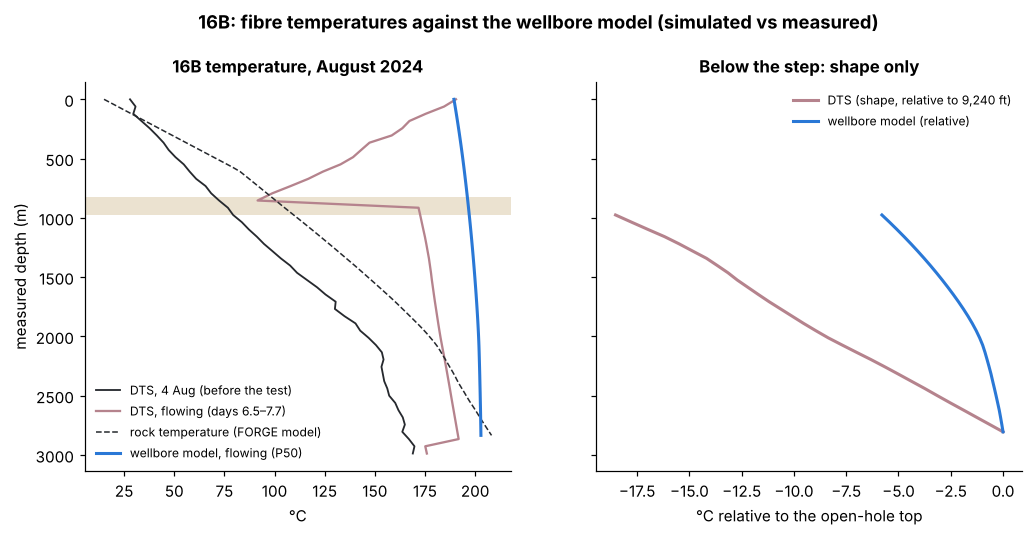

In [3]:
dts = pd.read_csv("data/dts_16B_2024.csv")
deep = json.loads(pathlib.Path("data/dts_16B_2024_deep.json").read_text())
D = E["dts"]
assert abs(deep["T_bottom_c"] - deep["T_top_c"] - D["deep"]["delta_c"]) < 0.05
sec = dts[(dts.md_ft >= 3200) & (dts.md_ft < 9200)]
slope = np.polyfit(sec.md_ft * 0.3048, sec.flowing_days_6p5_7p7_c, 1)[0] * 1000
assert abs(slope - D["deep"]["slope_c_per_km_md"]) / D["deep"]["slope_c_per_km_md"] < 0.05, slope
print(f"DTS, 9,240 → 3,200 ft: {D['deep']['delta_c']:.1f} °C of cooling (slope {D['deep']['slope_c_per_km_md']:.1f} °C per km along hole; scatter {D['deep']['sd_median_c']:.2f} °C)")
print(f"wellbore model on the same section: {pct(W['dts_section_delta_model_c'])} °C; upper bound (no insulation, highest conductivity): {pct(W['dts_section_delta_upper_bound_c'])} °C")
pr = W["profile_p50"]
dts = dts[dts.md_ft < 10000]                     # the last bin is past the end of the fibre
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
ax[0].plot(dts.static_4aug_c, dts.md_ft * 0.3048, color=CHARCOAL, lw=1.2, label="DTS, 4 Aug (before the test)")
ax[0].plot(dts.flowing_days_6p5_7p7_c, dts.md_ft * 0.3048, color=GRANITE, lw=1.5, label="DTS, flowing (days 6.5–7.7)")
ax[0].plot(pr["T_e"], pr["md_m"], "--", color=CHARCOAL, lw=1, label="rock temperature (FORGE model)")
ax[0].plot(pr["T_c"], pr["md_m"], color=BLUE, lw=2, label="wellbore model, flowing (P50)")
ax[0].axhspan(2700 * 0.3048, 3200 * 0.3048, color=FILL, alpha=0.5, lw=0)
ax[0].invert_yaxis(); ax[0].set_xlabel("°C"); ax[0].set_ylabel("measured depth (m)"); ax[0].set_title("16B temperature, August 2024"); ax[0].legend(fontsize=8, loc="lower left")
sel = (dts.md_ft >= 3200) & (dts.md_ft <= 9240)
o = np.argsort(pr["md_m"]); zz = dts.md_ft[sel] * 0.3048
Tm = np.interp(zz, np.array(pr["md_m"])[o], np.array(pr["T_c"])[o])
ax[1].plot(dts.flowing_days_6p5_7p7_c[sel] - dts.flowing_days_6p5_7p7_c[sel].iloc[-1], zz, color=GRANITE, lw=2, label="DTS (shape, relative to 9,240 ft)")
ax[1].plot(Tm - Tm[-1], zz, color=BLUE, lw=2, label="wellbore model (relative)")
ax[1].set_xlabel("°C relative to the open-hole top"); ax[1].set_title("Below the step: shape only"); ax[1].legend(fontsize=8)
fig.suptitle("16B: fibre temperatures against the wellbore model (simulated vs measured)", y=1.02, fontweight="bold")
fig.savefig("figures/forge_wellbore_dts.png")

**Reading it.** The wellbore model explains part of the misfit, not all of it. The DTS shape says the water cools about three times faster up the deep hole than conduction to the rock allows, even with no insulation. Two readings fit that: cooler water enters 16B higher up than the model's open cells (which would also explain the remaining bottom-hole misfit), or the fibre's calibration drifts along its length (it clearly does near 3,000 ft). This run cannot tell them apart. A production log (spinner and temperature) in 16B would.

## 3 · Apertures that respond to pressure (Barton–Bandis)

Each stimulated fracture closes or opens with the effective normal stress, Shmin − p (Barton–Bandis, normal stiffness 5–60 MPa/mm and maximum closure 0.1–0.5 mm, both ensemble parameters). The calibrated apertures are the apertures at the August 2024 pressures, so the fit to the test is kept. A rate is **feasible** when the injector bottom-hole pressure stays at or below Shmin at its top open cell for 30 years. Above Shmin new fractures would open; the model does not make them, so that is where it stops.

,apertures,rate (kg/s),"injector BHP, max (MPa)",Shmin (MPa),BHP / Shmin,feasible members,T year 30 (°C),"breakthrough (years, 35 m)"
0,constant apertures (phase 3),5,29.7 (29.1–30.1),40.3,0.74 (0.72–0.75),20/20,155.1 (137.3–169.8),3.65 (1.91–5.27)
1,constant apertures (phase 3),10,39.4 (38.2–40.2),40.3,0.98 (0.95–1.00),19/20,130.4 (116.5–147.8),1.78 (0.91–2.61)
2,constant apertures (phase 3),20,61.0 (58.7–62.4),40.3,1.51 (1.45–1.55),0/20,108.0 (99.6–126.0),0.85 (0.43–1.27)
3,constant apertures (phase 3),30,83.8 (80.8–86.0),40.3,2.08 (2.00–2.13),0/20,97.3 (91.8–114.9),0.55 (0.29–0.82)
4,constant apertures (phase 3),40,107.6 (102.4–110.0),40.3,2.67 (2.54–2.73),0/20,90.8 (87.1–107.9),0.40 (0.21–0.60)
5,Barton–Bandis,5,30.9 (30.0–32.5),40.3,0.77 (0.74–0.80),20/20,153.2 (136.4–169.4),3.50 (1.88–5.48)
6,Barton–Bandis,10,41.0 (39.6–41.8),40.3,1.01 (0.98–1.04),7/20,129.2 (115.7–146.9),1.71 (0.90–2.68)
7,Barton–Bandis,20,52.7 (49.6–56.0),40.3,1.31 (1.23–1.39),0/20,106.4 (99.3–123.3),0.86 (0.43–1.30)
8,Barton–Bandis,30,67.2 (59.8–72.9),40.3,1.67 (1.48–1.81),0/20,95.8 (91.1–110.3),0.55 (0.30–0.81)
9,Barton–Bandis,40,82.6 (70.0–89.2),40.3,2.05 (1.74–2.21),0/20,89.2 (86.2–102.9),0.36 (0.21–0.56)


highest feasible rate, constant apertures: 10.5 (10.1–11.0) kg/s
highest feasible rate, barton bandis: 9.7 (9.3–10.5) kg/s


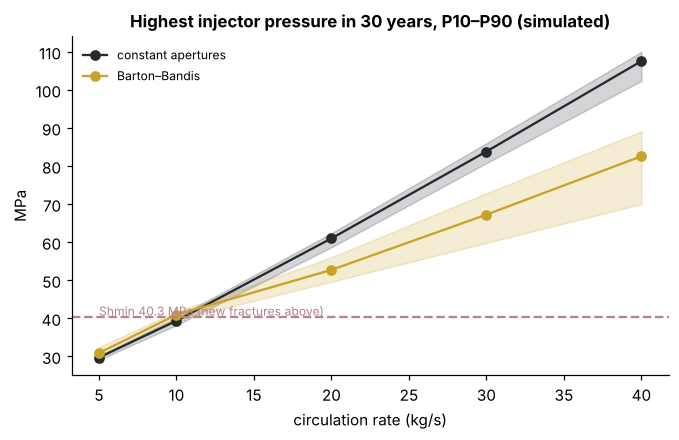

In [4]:
R = ens["rates"]
rows = []
for kind, lab in (("constant_apertures", "constant apertures (phase 3)"), ("barton_bandis", "Barton–Bandis")):
    for q, r in R[kind].items():
        if q == "max_feasible_rate_kg_s":
            continue
        rows.append({"apertures": lab, "rate (kg/s)": int(q), "injector BHP, max (MPa)": pct(r["injector_bhp_max_mpa"]),
                     "Shmin (MPa)": round(r["shmin_injector_mpa"], 1), "BHP / Shmin": pct(r["injector_bhp_over_shmin"], "{:.2f}"),
                     "feasible members": f"{r['feasible_members']}/{ens['members'] - ens['failed']}",
                     "T year 30 (°C)": pct(r["T_prod_end_c"]), "breakthrough (years, 35 m)": pct(r["breakthrough_years"], "{:.2f}")})
display(pd.DataFrame(rows))
for kind in ("constant_apertures", "barton_bandis"):
    print(f"highest feasible rate, {kind.replace('_', ' ')}: {pct(R[kind]['max_feasible_rate_kg_s'])} kg/s")
fig, ax = plt.subplots(figsize=(7, 4))
for kind, c, lab in (("constant_apertures", CHARCOAL, "constant apertures"), ("barton_bandis", GOLD, "Barton–Bandis")):
    qs = [int(q) for q in R[kind] if q != "max_feasible_rate_kg_s"]
    b = [R[kind][str(q)]["injector_bhp_max_mpa"] for q in qs]
    ax.fill_between(qs, [x["P10"] for x in b], [x["P90"] for x in b], color=c, alpha=0.2)
    ax.plot(qs, [x["P50"] for x in b], "o-", color=c, label=lab)
sh = R["barton_bandis"]["10"]["shmin_injector_mpa"]
ax.axhline(sh, color=GRANITE, ls="--"); ax.text(qs[0], sh + 0.4, f"Shmin {sh:.1f} MPa (new fractures above)", color=GRANITE, fontsize=8)
ax.set_xlabel("circulation rate (kg/s)"); ax.set_ylabel("MPa"); ax.set_title("Highest injector pressure in 30 years, P10–P90 (simulated)"); ax.legend(fontsize=8)
fig.savefig("figures/forge_barton_bandis.png")

In [5]:
VB, VC = V["barton_bandis"], V["constant_apertures"]
print(f"August test with Barton–Bandis: produced {pct(VB['produced_kg_s'])} kg/s, recovery {pct(VB['recovery'], '{:.3f}')} "
      f"(measured {V['measured']['measured_produced_kg_s']:.1f} kg/s, {V['measured']['measured_recovery']:.3f}); "
      f"build-up misfit, worst day 4–15: {pct(VB['buildup_misfit_mpa_days4_15_max_abs'])} MPa (constant apertures {pct(VC['buildup_misfit_mpa_days4_15_max_abs'])})")

August test with Barton–Bandis: produced 24.8 (23.9–25.3) kg/s, recovery 0.936 (0.903–0.955) (measured 24.5 kg/s, 0.926); build-up misfit, worst day 4–15: 5.7 (4.2–8.0) MPa (constant apertures 7.7 (6.4–9.2))


## 4 · Tracers: travel time between the wells

QuantumPro injected ten nanoparticle tracers into 16A during the August test, one every two days, and sampled 16B every few hours. The first-detection times are recomputed here from `data/tracers_2024_circulation.csv`: between the last clean and the first positive sample. For tracers 5–10 the first sample after injection was already positive, so only an upper bound is known. The model injects a 30-minute pulse at the August flow and tracks it in the fracture porosity only (nanoparticles do not enter the granite matrix).

,tracer,first detection (h),peak sample (h),measured / modelled first arrival,measured / modelled peak
0,1,28.1–34.1,40.1,842–1022 ×,80 ×
1,2,58.5–64.5,82.5,1755–1936 ×,165 ×
2,3,10.5–16.5,58.5,315–496 ×,117 ×
3,4,4.5–10.5,16.5,135–315 ×,33 ×
4,5,< 10.7,178.5,< 321 ×,357 ×
5,6,< 10.5,106.5,< 315 ×,213 ×
6,7,< 10.4,34.5,< 313 ×,69 ×
7,8,< 10.5,10.5,< 314 ×,21 ×
8,9,< 10.4,10.4,< 313 ×,21 ×
9,10,< 10.5,34.5,< 315 ×,69 ×


model (fracture porosity): first arrival 0.03 (0.03–0.06) h, peak 0.50 (0.50–0.63) h, mean residence 4.8 (2.4–14.8) h, pore volume 2711 (1386–8886) m³
to match the measured first arrivals, the mobile pore volume would have to be 75–1936 × larger; to match the peaks 17–357 ×


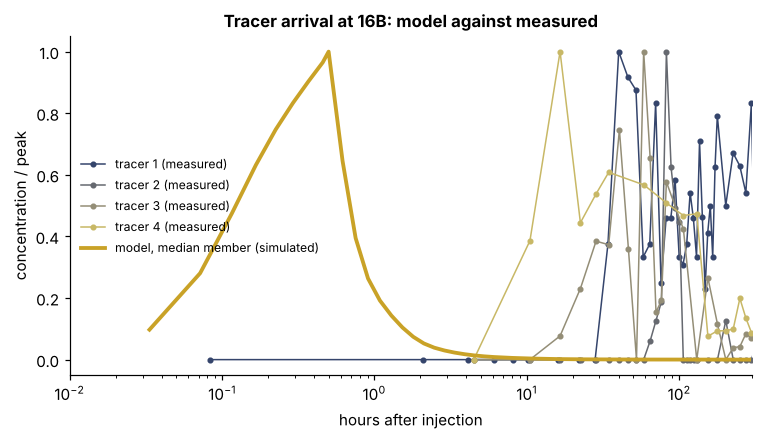

In [6]:
trc = pd.read_csv("data/tracers_2024_circulation.csv")
meas = {x["tracer"]: x for x in E["tracers_measured"]["summary"] if x.get("detected")}
for t, g in trc.groupby("tracer"):
    a = g[g.sample_t_h > g.injected_t_h.iloc[0]]
    ta, c = (a.sample_t_h - a.injected_t_h).values, a.c_ppb.values
    i = int(np.argmax(c > 0))
    assert abs(ta[i] - meas[t]["first_positive_h"]) < 0.02 and abs(ta[np.argmax(c)] - meas[t]["peak_h"]) < 0.02, t
TV = E["tracer_validation"]
rows = [{"tracer": r["tracer"], "first detection (h)": (f"{r['first_detection_bracket_h'][0]:.1f}–{r['first_detection_bracket_h'][1]:.1f}" if r["lower_bound_known"] else f"< {r['first_detection_bracket_h'][1]:.1f}"),
         "peak sample (h)": round(r["peak_h"], 1), "measured / modelled first arrival": (f"{r['ratio_first_vs_model_P50'][0]:.0f}–{r['ratio_first_vs_model_P50'][1]:.0f} ×" if r["lower_bound_known"] else f"< {r['ratio_first_vs_model_P50'][1]:.0f} ×"),
         "measured / modelled peak": f"{r['ratio_peak_vs_model_P50']:.0f} ×"}
        for r in TV["tracers"]]
display(pd.DataFrame(rows))
T4 = ens["tracer"]
print(f"model (fracture porosity): first arrival {pct(T4['first_arrival_1pct_peak_h'], '{:.2f}')} h, peak {pct(T4['peak_time_h'], '{:.2f}')} h, "
      f"mean residence {pct(T4['mean_residence_h'], '{:.1f}')} h, pore volume {pct(T4['pore_volume_m3'], '{:.0f}')} m³")
print(f"to match the measured first arrivals, the mobile pore volume would have to be {TV['porosity_factor_to_match_first_arrival'][0]:.0f}–{TV['porosity_factor_to_match_first_arrival'][1]:.0f} × larger; "
      f"to match the peaks {TV['porosity_factor_to_match_peak'][0]:.0f}–{TV['porosity_factor_to_match_peak'][1]:.0f} ×")
cm = E["median_member"]["tracer"]["curve"]
fig, ax = plt.subplots(figsize=(8, 4))
for t, g in trc.groupby("tracer"):
    a = g[g.sample_t_h > g.injected_t_h.iloc[0]]
    if a.c_ppb.max() > 0 and t <= 4:
        ax.plot(a.sample_t_h - a.injected_t_h, a.c_ppb / a.c_ppb.max(), "o-", ms=3, lw=1, color=plt.get_cmap("cividis")(t / 5), label=f"tracer {t} (measured)")
ax.plot(cm["t_h"], cm["c_rel"], color=GOLD, lw=2.5, label="model, median member (simulated)")
ax.set_xscale("log"); ax.set_xlim(0.01, 300); ax.set_xlabel("hours after injection"); ax.set_ylabel("concentration / peak")
ax.set_title("Tracer arrival at 16B: model against measured"); ax.legend(fontsize=8)
fig.savefig("figures/forge_tracers.png")

**Reading it.** The model's water arrives far too early. Its first arrival falls inside the first time step (2 minutes) and its peak at the end of the 30-minute pulse, so the modelled times are upper bounds and the ratios above are lower bounds on the misfit. With hydraulic apertures (the apertures that fit the pressure, cubic law), the fracture pore volume between the wells is small, so a pulse crosses in minutes to an hour; the tracers took hours to days. Fractures with rough walls hold much more water than their hydraulic aperture says, so a transport aperture larger than the hydraulic one is expected. The factor above is how much larger the mobile pore volume would have to be. The model is not calibrated to the tracers here: doing so changes no pressure and no rate, but it slows the cooling front only if the extra volume also exchanges heat with the rock, which is an open question (see the end of this notebook). This is the most important misfit of phase 4.

## Published numbers

In [7]:
now = {"T_bottom_implied_P50": W["T_bottom_implied_c"]["P50"], "cooling_from_model_P50": W["cooling_from_model_c"]["P50"],
       "cooling_from_model_P10": W["cooling_from_model_c"]["P10"], "cooling_from_model_P90": W["cooling_from_model_c"]["P90"],
       "misfit_bh_P50": V["constant_apertures"]["T_misfit_bottomhole_c"]["P50"], "misfit_bh_P10": V["constant_apertures"]["T_misfit_bottomhole_c"]["P10"],
       "misfit_bh_P90": V["constant_apertures"]["T_misfit_bottomhole_c"]["P90"], "phase3_gap_after_ramey_c": gap3, "explained_c": expl,
       "dts_delta_measured": D["deep"]["delta_c"], "dts_delta_model_P50": W["dts_section_delta_model_c"]["P50"], "dts_delta_upper_P90": W["dts_section_delta_upper_bound_c"]["P90"]}
for kind in ("constant_apertures", "barton_bandis"):
    for p in ("P10", "P50", "P90"):
        now[f"max_rate_{kind}_{p}"] = R[kind]["max_feasible_rate_kg_s"][p]
    for q in ("10", "20", "40"):
        now[f"feasible_{kind}_{q}"] = R[kind][q]["feasible_members"]
        now[f"bhp_max_{kind}_{q}_P50"] = R[kind][q]["injector_bhp_max_mpa"]["P50"]
for k in ("first_arrival_1pct_peak_h", "peak_time_h", "mean_residence_h"):
    for p in ("P10", "P50", "P90"):
        now[f"tracer_{k}_{p}"] = T4[k][p]
now["tracer_factor_first_lo"], now["tracer_factor_first_hi"] = TV["porosity_factor_to_match_first_arrival"]
check(now, "nb4b")

all 41 published numbers reproduced


## What this says, and what it does not

* **Wellbore.** Heat loss up 16B is 14.4 °C (P10–P90 13.5–15.4) from the model's bottom-hole temperature. The measured wellhead then implies 202.9 °C (200.0–205.9) at the bottom hole. The reservoir model gives 214.0 °C, so **+11.2 °C (9.7–12.6) remains**. The wellbore model explains about 2 °C of the 13 °C left in notebook 3.
* **DTS.** Up the deep hole the fibre shows 18.4 °C of cooling; conduction to the rock allows 5.8 °C (at most 8.2). Either cooler water enters 16B higher up, or the fibre drifts. Not resolved here.
* **Barton–Bandis.** **No rate above 10 kg/s becomes feasible.** The highest feasible rate is 9.7 kg/s (9.3–10.5), against 10.5 (10.1–11.0) with constant apertures. The apertures are calibrated at the August pressure, which was already above Shmin (42.9 against 40.3 MPa). Below it the fractures close; they open further only above Shmin, where new fractures would form.
* **Tracers.** The model's water crosses in under 30 minutes. The tracers took 4.5–64 hours to first appear and 10–180 hours to peak. The mobile pore volume would have to be at least 17–360 × larger. This is the largest misfit in the case.

**Limits.** Equivalent continuum on 35 m cells. Feasibility depends on the grid: at 10 kg/s the median member's highest injector pressure is 2.9 MPa lower on 23.3 m cells than on 35 m cells. Shmin is a depth gradient, not a measurement at 16A. One calibration number (the August injection pressure). Single-phase water, no new fractures.

*References:* Hasan, A. R. and Kabir, C. S. (1991). Heat transfer during two-phase flow in wellbores. SPE 22866 · Barton, N., Bandis, S. and Bakhtar, K. (1985). Strength, deformation and conductivity coupling of rock joints. Int. J. Rock Mech. Min. Sci. 22(3) · McLennan, J., England, K. and Swearingen, L. (2024). GDR 1683, DOI 10.15121/2475065 · Guo, Oliver and Shokanov (2024). GDR 1701, DOI 10.15121/2507443 · Neubrex (2024). GDR 1721.